### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [27]:
data = pd.read_csv ('coupons.csv')

In [28]:
data.head ()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [29]:
missing_values = data.isnull ().sum ()
print ("Missing values per column:\n", missing_values[missing_values > 0])
data.info ()

Missing values per column:
 car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  s

3. Decide what to do about your missing data -- drop, replace, other...

In [30]:
# The 'Car' column ontains missing; drop it.
if 'Car' in data.columns:
    data = data.drop (columns=['Car'])

# minor missing values (like Bar, CoffeeHouse, CarryAway), 
# NaN values or fill them. Here we drop remaining NaNs for clean analysis:

data = data.dropna ()
print (f"Dataset shape after cleaning missing data: {data.shape}")


Dataset shape after cleaning missing data: (108, 26)


4. What proportion of the total observations chose to accept the coupon?



In [31]:
acceptance_proportion = data['Y'].mean()
print (f"Proportion of total observations that accepted the coupon: {acceptance_proportion:.4f} ({acceptance_proportion * 100:.2f}%)")

Proportion of total observations that accepted the coupon: 0.5741 (57.41%)


5. Use a bar plot to visualize the `coupon` column.

/tmp/ipykernel_27282/2928109960.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot (data=data, x='coupon', order=data['coupon'].value_counts().index, palette='viridis')


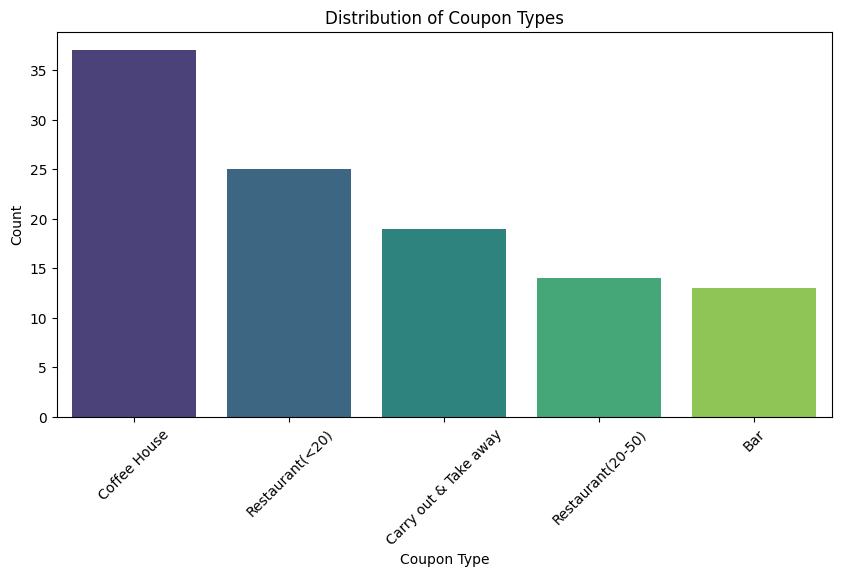

In [32]:
plt.figure (figsize=(10, 5))
sns.countplot (data=data, x='coupon', order=data['coupon'].value_counts().index, palette='viridis')
plt.title ('Distribution of Coupon Types')
plt.xlabel ('Coupon Type')
plt.ylabel ('Count')
plt.xticks (rotation=45)
plt.show ()

6. Use a histogram to visualize the temperature column.

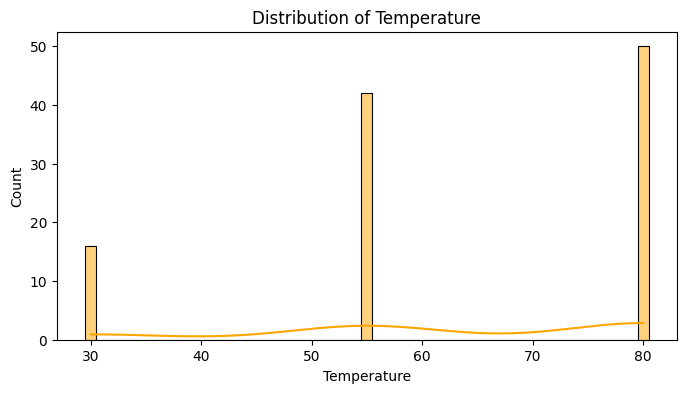

In [33]:
plt.figure (figsize=(8, 4))
sns.histplot (data=data, x='temperature', discrete=True, kde=True, color='orange')
plt.title ('Distribution of Temperature')
plt.xlabel ('Temperature')
plt.ylabel ('Count')
plt.sho w()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [37]:
bar_data = data[data['coupon'] == 'Bar'].copy()

print (f"Number of bar coupon observations: {len(bar_data)}")

Number of bar coupon observations: 13


2. What proportion of bar coupons were accepted?


In [36]:
bar_acceptance_rate = bar_data['Y'].mean ()
print (f"Bar coupon acceptance rate: {bar_acceptance_rate:.4f} ({bar_acceptance_rate * 100:.2f}%)")

Bar coupon acceptance rate: 0.2308 (23.08%)


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [35]:
#Categories: 'never', 'less1', '1~3', '4~8', 'gt8'
low_bar = bar_data[bar_data['Bar'].isin(['never', 'less1', '1~3'])]
high_bar = bar_data[bar_data['Bar'].isin(['4~8', 'gt8'])]

print (f"Acceptance rate (3 or fewer times/month): {low_bar['Y'].mean():.4f}")
print (f"Acceptance rate (More than 3 times/month): {high_bar['Y'].mean():.4f}")


Acceptance rate (3 or fewer times/month): 0.0909
Acceptance rate (More than 3 times/month): 1.0000


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [41]:
#function to convert age strings to numeric values
def clean_age (val):
    if val == 'below21':
        return 20
    elif val == '50+':
        return 51
    else:
        try:
            return float (val)
        except:
            return np.nan

bar_data['age_num'] = bar_data['age'].apply (clean_age)

#condition: Bar > 1 time/month ('1~3', '4~8', 'gt8') AND age > 25
cond1 = (bar_data['Bar'].isin (['1~3', '4~8', 'gt8'])) & (bar_data['age_num'] > 25)

rate1 = bar_data[cond1]['Y'].mean()
rate_others1 = bar_data[~cond1]['Y'].mean()

print (f"Acceptance rate (Bar > 1/mo & Age > 25): {rate1:.4f}")
print (f"Acceptance rate (All others): {rate_others1:.4f}")

Acceptance rate (Bar > 1/mo & Age > 25): 1.0000
Acceptance rate (All others): 0.0909


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [42]:

cond2 = (
    bar_data['Bar'].isin(['1~3', '4~8', 'gt8']) &
    (bar_data['passanger'] != 'Kid(s)') &
    (bar_data['occupation'] != 'Farming Fishing & Forestry')
)

rate2 = bar_data[cond2]['Y'].mean()
rate_others2 = bar_data[~cond2]['Y'].mean()

print (f"Acceptance rate (Target group): {rate2:.4f}")
print (f"Acceptance rate (All others): {rate_others2:.4f}")


Acceptance rate (Target group): 1.0000
Acceptance rate (All others): 0.0909


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [43]:
low_income = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']

rule1 = (
    bar_data['Bar'].isin(['1~3', '4~8', 'gt8']) &
    (bar_data['passanger'] != 'Kid(s)') &
    (bar_data['maritalStatus'] != 'Widowed')
)

rule2 = (
    bar_data['Bar'].isin(['1~3', '4~8', 'gt8']) &
    (bar_data['age_num'] < 30)
)

rule3 = (
    bar_data['RestaurantLessThan20'].isin(['4~8', 'gt8']) &
    bar_data['income'].isin(low_income)
)

combined_cond = rule1 | rule2 | rule3

print(f"Acceptance rate for combined rules: {bar_data[combined_cond]['Y'].mean():.4f}")
print(f"Acceptance rate for all others: {bar_data[~combined_cond]['Y'].mean():.4f}")

Acceptance rate for combined rules: 1.0000
Acceptance rate for all others: 0.0909


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [ ]:
Drivers who frequently visit bars (more than once a month) and are social (traveling with friends or partners rather than kids) exhibit a significantly higher acceptance rate for bar coupons. Habitual behavior and social context are strong predictors of coupon utilization.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

Coffee House Coupon Acceptance Rate: 0.5135

Acceptance Rate by Coffee House Visit Frequency:
CoffeeHouse
1~3      0.571429
4~8      0.500000
less1    0.500000
Name: Y, dtype: float64

Acceptance Rate by Time of Day:
time
10AM    0.444444
10PM    0.500000
2PM     0.625000
6PM     0.416667
7AM     0.666667
Name: Y, dtype: float64


/tmp/ipykernel_27282/254729125.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=coffee_data, x='CoffeeHouse', y='Y', hue='time', palette='muted', ci=None)


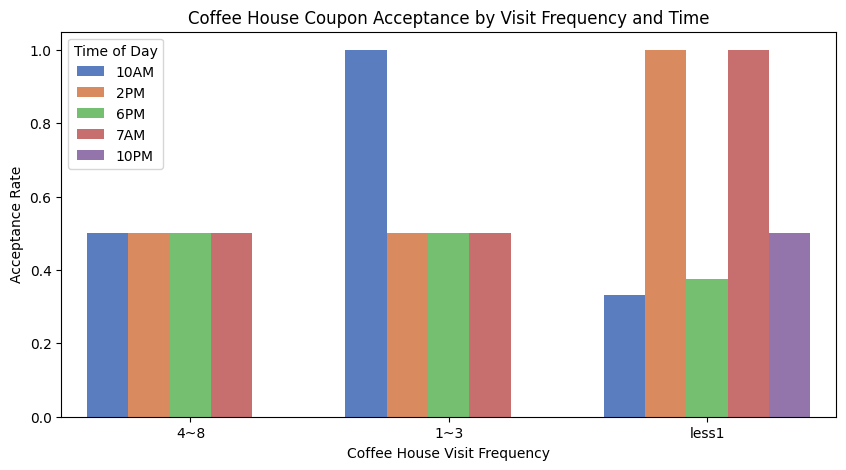

In [44]:
#Filter for Coffee House coupons
coffee_data = data[data['coupon'] == 'Coffee House'].copy()

#Overall Coffee House acceptance rate
coffee_acceptance = coffee_data['Y'].mean()
print(f"Coffee House Coupon Acceptance Rate: {coffee_acceptance:.4f}")

#Acceptance rate by visit frequency
print("\nAcceptance Rate by Coffee House Visit Frequency:")
print(coffee_data.groupby('CoffeeHouse')['Y'].mean())

#Acceptance rate by time of day
print("\nAcceptance Rate by Time of Day:")
print(coffee_data.groupby('time')['Y'].mean())

#Visualization: Acceptance rate by Coffee House frequency and time
plt.figure(figsize=(10, 5))
sns.barplot(data=coffee_data, x='CoffeeHouse', y='Y', hue='time', palette='muted', ci=None)
plt.title('Coffee House Coupon Acceptance by Visit Frequency and Time')
plt.xlabel('Coffee House Visit Frequency')
plt.ylabel('Acceptance Rate')
plt.legend(title='Time of Day')
plt.show()
